# ACTIVITY 2: SIMPLE HOUSE PRICE PREDICTION

**Unit:** Unit II – Supervised Learning: Regression

**Objective:** To develop a Linear Regression model to predict house prices using property features and evaluate its performance.

### Dataset Information

- **Dataset Name:** Ames Housing Dataset
- **Source:** [Ames Housing Dataset – CSV](https://huggingface.co/datasets/Causal-Copilot/Causal-Copilot-Dataset/resolve/main/realworld_data/AmesHousing.csv)
- **Description:** The dataset contains information about residential properties in Ames, Iowa, including living area, bedrooms, quality and selling prices.
- **Input Feature (X):** GrLivArea (Above-ground living area in square feet).
- **Target Variable (y):** SalePrice (House selling price in dollars).

### Problem Statement

To build a Simple Linear Regression model that predicts house prices based on the living area of a property.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/AmesHousing.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


The Ames Housing dataset is loaded using the Pandas library. The dataset is inspected to understand its structure, number of records, column names, data types and statistical information.

Missing values and duplicate records are also checked to understand the quality of the data.

In [22]:
# Display first five records
display(df.head())

# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Number of rows and columns: (2930, 82)

Column Names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'G

In [23]:
# Summary statistics
display(df.describe())

# Check missing values
print("Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


Missing Values:
15749
Duplicate Records: 0


##Input Features and Target
- Gr Liv Area represents the above-ground living area of a house in square feet.
- SalePrice represents the actual selling price of the house in dollars.

Living area is selected because larger houses generally have higher selling prices.

In [24]:
# Select input feature and target variable

X = df[['Gr Liv Area']]
y = df['SalePrice']

# Remove missing or invalid values from selected columns
data = pd.concat([X, y], axis=1)
data = data.dropna()

# Update X and y
X = data[['Gr Liv Area']]
y = data['SalePrice']

print("Input Feature:", X.columns.tolist())
print("Target Variable:", y.name)
print("Total Records:", len(data))

display(data.head())

Input Feature: ['Gr Liv Area']
Target Variable: SalePrice
Total Records: 2930


,Gr Liv Area,SalePrice
0,1656,215000
1,896,105000
2,1329,172000
3,2110,244000
4,1629,189900


In [25]:
print("\nData Types:")
print(data.dtypes)

print("\nIs SalePrice numerical?",
      pd.api.types.is_numeric_dtype(data['SalePrice']))

print("Is SalePrice continuous?",
      data['SalePrice'].nunique() > 1)


Data Types:
Gr Liv Area    int64
SalePrice      int64
dtype: object

Is SalePrice numerical? True
Is SalePrice continuous? True


##Visualise the Relationship

A scatter plot is used to examine the relationship between the living area of houses and their selling prices.

The plot helps identify whether an increase in living area is associated with an increase or decrease in house price. However, a visible relationship does not prove causation.

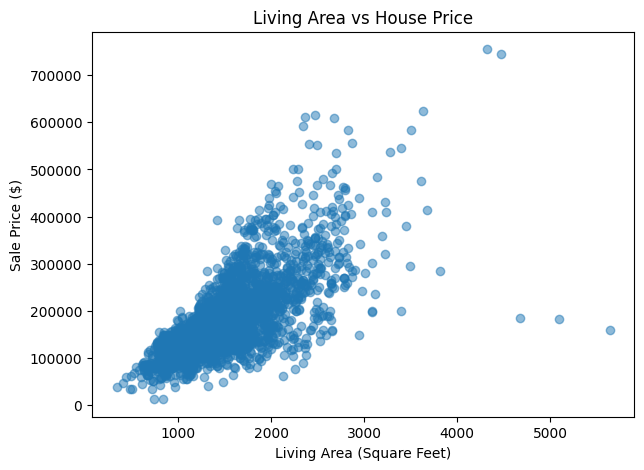

In [35]:
plt.figure(figsize=(7,5))

plt.scatter(X['Gr Liv Area'], y, alpha=0.5)

plt.title('Living Area vs House Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('Sale Price ($)')

plt.show()

### Observation

The scatter plot shows a generally positive relationship between living area and house price. As the living area increases, the selling price generally increases. However, some variations and outliers are also visible.

This relationship does not necessarily prove that living area alone causes an increase in house prices.

##Split the Data into Training and Testing Sets


In [27]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Total Records:", len(X_train) + len(X_test))

Training Records: 2344
Testing Records: 586
Total Records: 2930


### Observation

The dataset containing 2,930 records was divided into 2,344 training records (80%) and 586 testing records (20%). The training set will be used to train the model, while the testing set will be used to evaluate its performance on unseen data.

##Train a Linear Regression Model

Linear Regression is a supervised learning algorithm used to predict continuous numerical values.

In this project, the model learns the relationship between the living area of a house and its selling price using the training dataset.

### Linear Regression Equation

**Ŷ = β₀ + β₁X**

Where:

- Ŷ = Predicted house price
- β₀ = Intercept (constant value)
- β₁ = Regression coefficient (slope)
- X = Living area of the house

The model learns the values of β₀ and β₁ during training.

In [28]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display coefficient and intercept
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 106.72915508271505
Intercept: 19250.559555372573


In [29]:
beta_0 = model.intercept_
beta_1 = model.coef_[0]

print("Beta 0 (Intercept):", beta_0)
print("Beta 1 (Coefficient):", beta_1)

print("\nLinear Regression Equation:")
print(f"SalePrice = {beta_0:.2f} + ({beta_1:.2f} × Gr Liv Area)")

Beta 0 (Intercept): 19250.559555372573
Beta 1 (Coefficient): 106.72915508271505

Linear Regression Equation:
SalePrice = 19250.56 + (106.73 × Gr Liv Area)


### Interpretation

- **β₀ (Intercept):** Represents the predicted house price when the living area is zero.
- **β₁ (Coefficient):** Represents the change in predicted house price for every additional square foot of living area.
- A positive coefficient indicates that house prices generally increase as living area increases.

The model uses these learned values to predict house prices.

Generate Predictions

to predict house prices for the testing data and compare them with the actual prices.

In [30]:
# Generate predictions using test data
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

# Display first 10 comparisons
display(comparison.head(10))

,Actual Price,Predicted Price
1357,161000,197061.331923
2367,116000,129181.589291
2822,196500,203251.622918
2126,123600,124912.423087
1544,126000,117334.653076
2415,174190,160773.419195
2227,200000,128114.297740
410,148500,174648.209356
761,88750,94387.884734
436,409900,288208.030364


**Evaluate the Model**

using MAE, MSE, RMSE and R² score to measure prediction errors and model performance.

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 41365.51131849474
Mean Squared Error (MSE): 3821184066.2726417
Root Mean Squared Error (RMSE): 61815.72669048421
R2 Score: 0.5233974153691151


### Evaluation Metrics

- **MAE:** Average absolute difference between actual and predicted prices.
- **MSE:** Average of squared prediction errors. It gives more weight to larger errors.
- **RMSE:** Square root of MSE. It expresses prediction error in the same unit as house prices (dollars).
- **R² Score:** Measures how well the model performs compared with predicting the average house price. A negative R² means the model performs worse than this mean-based baseline on the test data.

### Observation

- MAE is approximately $41,366, meaning the average absolute prediction error is around $41,366.

- RMSE is approximately $61,816, showing the typical error magnitude with greater penalty for large errors.

- R² score is 0.5234, which means the model explains about 52.34% of the variation in house prices.

The model shows a moderate performance, but its predictions can still differ considerably from actual house prices.

##Visualise Actual vs Predicted Values- A scatter plot is used and the diagonal line represents perfect predictions.

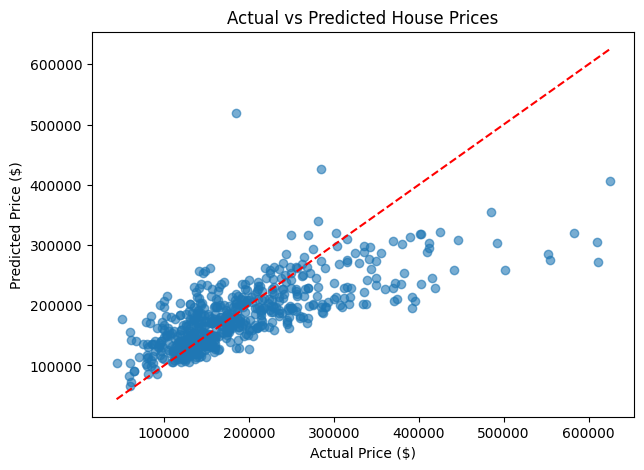

In [32]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot([min_price, max_price],
         [min_price, max_price], 'r--')

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')

plt.show()

### Observation

The points show the difference between actual and predicted house prices. Points closer to the diagonal line represent more accurate predictions. Some points are farther away, indicating prediction errors.### Observation

The graph shows a positive relationship between actual and predicted house prices. Most points are near the diagonal line, but some are far from it, indicating prediction errors. The model performs reasonably well but is not perfectly accurate.

## Predict a New House Price - Using the trained model to predict the selling price of a new house based on its living area.

In [33]:
new_house = pd.DataFrame({'Gr Liv Area': [3000000]})
predicted_price = model.predict(new_house)

print("Living Area:", 3000000, "sq. ft.")
print("Predicted House Price: $", round(predicted_price[0], 2))

Living Area: 3000000 sq. ft.
Predicted House Price: $ 320206715.81


In [34]:
new_house = pd.DataFrame({'Gr Liv Area': [1500]})

# Check whether input is within training data range
print("Training Area Range:",
      X_train['Gr Liv Area'].min(), "to",
      X_train['Gr Liv Area'].max())

predicted_price = model.predict(new_house)

print("Living Area: 1500 sq. ft.")
print("Predicted House Price: $", round(predicted_price[0], 2))

Training Area Range: 334 to 5642
Living Area: 1500 sq. ft.
Predicted House Price: $ 179344.29


## Conclusion

In this activity, a Simple Linear Regression model was developed using the Ames Housing Dataset.

- **Input Feature:** Gr Liv Area (Living Area in square feet).

- **Target Variable:** SalePrice (House Price in dollars).

- **Model Used:** Linear Regression.

- **MAE:** $41,365.51

- **MSE:** 3,821,184,066.27

- **RMSE:** $61,815.73

- **R² Score:** 0.5234

The model was used to predict house prices and evaluated using different performance metrics.

The model provides moderately accurate predictions. However, house prices depend on several factors such as location, number of bedrooms, quality and age. Since this model uses only living area, it cannot capture all factors affecting house prices.